### Prediction Diabetes with Multilayer Perceptron

#### Import Libraries

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
from keras.regularizers import l2
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

#### Importing the data

In [ ]:
df = pd.read_csv("data/diabetes.csv")

In [53]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


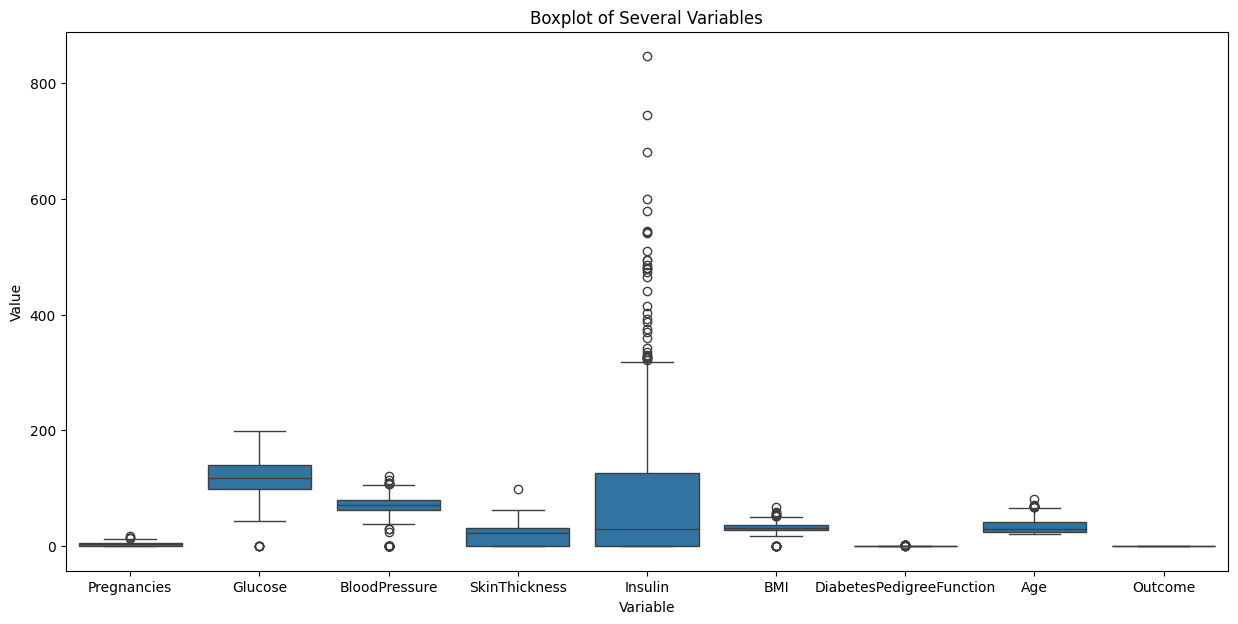

In [54]:
df_melted = df.melt(var_name="Variable", value_name="Value")
plt.figure(figsize=(15, 7))
sns.boxplot(x='Variable', y='Value', data=df_melted)
plt.title("Boxplot of Several Variables")
plt.show()

Insulin values seem to have a broader distribution, with more outliers.

C:\Users\asus\AppData\Local\Temp\ipykernel_22296\3227882625.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(
C:\Users\asus\AppData\Local\Temp\ipykernel_22296\3227882625.py:15: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


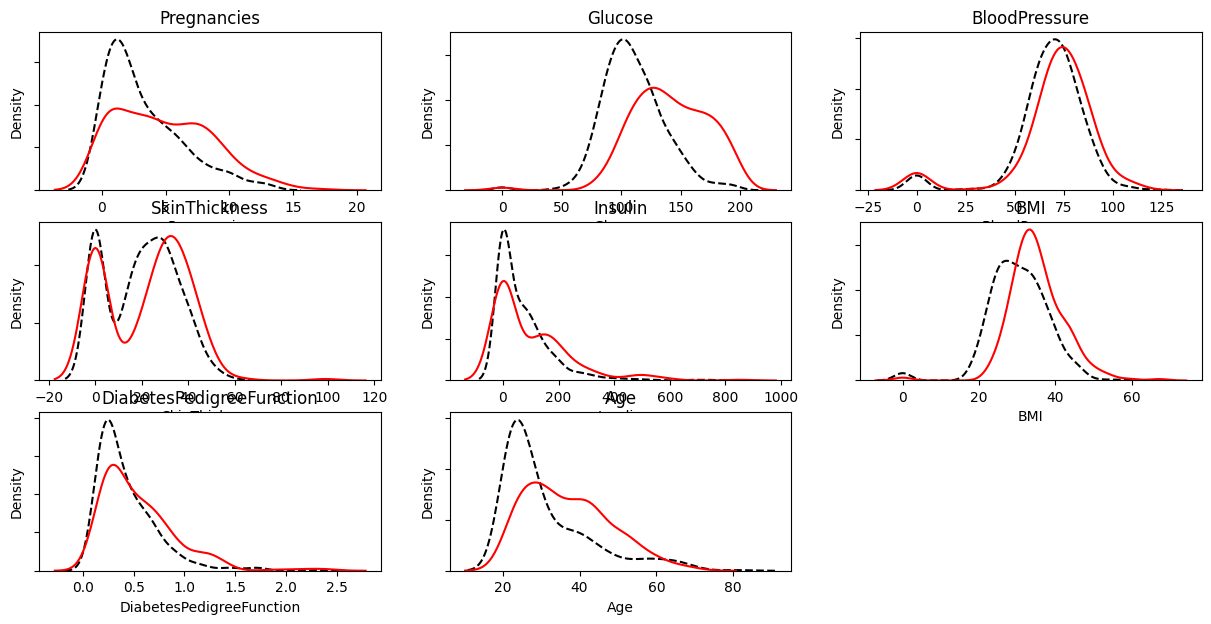

In [55]:
plt.subplots(3,3,figsize=(15,7))

# Plot a density plot for each variable
for idx, col in enumerate(df.columns):
    ax = plt.subplot(3,3,idx+1)
    ax.yaxis.set_ticklabels([])
    sns.kdeplot(
    data=df[df.Outcome == 0],
    x=col,
    ax=ax,
    linestyle='--',
    color='black',
    label="No Diabetes"
    )
    sns.kdeplot(
    data=df[df.Outcome == 1],
    x=col,
    ax=ax,
    linestyle='-',
    color='red',
    label="Diabetes"
    )
    ax.set_title(col)
    
#Hide the 9th subplot (bottom right since there are only 8 plots)
plt.subplot(3,3,9).set_visible(False)

plt.show()

Density Analysis:
- Pregnancies: Similar distribution for diabetic and non-diabetic patients.
- Glucose: Higher glucose levels observed in diabetic patients.
- Blood Pressure: Similar distribution across both groups.
- Skin Thickness: Similar distribution across both groups.
- Insulin: Similar distribution across both groups.
- BMI: Slightly higher BMI values among diabetic patients.
- Diabetes Pedigree Function: Similar distribution in both groups.
- Age: Diabetic patients tend to be older.

#### Missing data

In [56]:
df.isnull().any()
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [57]:
zero_check_cols = df.columns.difference(['Pregnancies', 'Outcome']) ## excluded pregnancies because is valid that a patient wasn't pregnant before
(df[zero_check_cols] == 0).sum()

Age                           0
BMI                          11
BloodPressure                35
DiabetesPedigreeFunction      0
Glucose                       5
Insulin                     374
SkinThickness               227
dtype: int64

Zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` are not valid values, so I treat them as missing and replace them with `NaN`. This rule doesn't use any statistics from the data, so it's safe to apply before splitting.

I don't impute the missing values here. Mean and KNN imputation use information from the other rows, so I do it after the split and fit it on the training set only. I compare mean and KNN imputation with cross-validation at the end of the notebook.

In [58]:
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[invalid_zero_cols] = df[invalid_zero_cols].replace(0, np.nan)

df[invalid_zero_cols].isna().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

#### Data Standardization and Imputation

I fit both steps on the training set only (see the next section) and then apply them to the validation and test sets. Fitting them on the full dataset would leak information from the test set into the training.

In [59]:
df_scaled = preprocessing.scale(df)
df_scaled = pd.DataFrame(df_scaled,columns=df.columns)
df_scaled['Outcome'] = df['Outcome']
df = df_scaled

df.describe().loc[['mean','std','max'],].round(2).abs()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.35
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.48
max,3.91,2.53,4.01,6.67,5.82,5.01,5.88,4.06,1.00


#### Class Imbalance

In [60]:
df.groupby('Outcome').count()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,500,497,481,361,264,491,500,500
1,268,266,252,180,130,266,268,268


There's a class imbalance in the dataset, so it's important to handle it after splitting the data. That way, only the training set is balanced, and the validation and test sets still reflect the real-world distribution. This helps avoid misleading results and keeps the model evaluation realistic.

#### Data Splitting

I split the dataset into three parts:
- Training set (64%): used to train the neural network
- Validation set (16%): used to tune the hyperparameters
- Test set (20%): used at the end to evaluate how well the model performs on unseen data

All splits are stratified, so they keep the same proportion of diabetic patients.

In [61]:
X = df.drop(columns='Outcome')
y = df['Outcome']

# first, I divide off the test set, then I split the rest into training and validation sets
# stratify keeps the same proportion of diabetic patients in every split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)


def make_preprocessor(imputer=None):
    # imputation followed by standardization (mean imputation by default)
    if imputer is None:
        imputer = SimpleImputer(strategy='mean')
    return Pipeline([('imputer', imputer), ('scaler', StandardScaler())])


# fit on the training set only, then apply the same transformation to validation and test
preprocessor = make_preprocessor()
X_train = pd.DataFrame(preprocessor.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_val = pd.DataFrame(preprocessor.transform(X_val), columns=X.columns, index=X_val.index)
X_test = pd.DataFrame(preprocessor.transform(X_test), columns=X.columns, index=X_test.index)

X_train.describe().loc[['mean', 'std']].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Class Imbalance - applied to the training set

In [62]:
class_weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
class_weight_dict = dict(enumerate(class_weights))


#### Data Modelling

In [63]:
# tuned model

def build_model(hp):
    model = Sequential()

    l2_strength = hp.Float("l2_strength", min_value=1e-5, max_value=1e-2, sampling="log")

    # tune the number of units in the first Dense layer between 16 and 64 (step 16)
    model.add(Dense(units=hp.Int('units_1', min_value=16, max_value=64, step=16), 
                    activation='relu', input_dim=8, kernel_regularizer=l2(l2_strength)))
    model.add(Dropout(0.3))
    
    # tune the number of units in the second Dense layer between 8 and 32 (step 8)
    model.add(Dense(units=hp.Int('units_2', min_value=8, max_value=32, step=8), activation='relu', kernel_regularizer=l2(l2_strength)))
    model.add(Dropout(0.3))
    
    model.add(Dense(1, activation='sigmoid'))
    
    # tune the learning rate for the Adam optimizer
    lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,             # max number of hyperparameter combinations to try
    executions_per_trial=1,    # number of model trainings per trial (for stability)
    directory='my_dir',        # where to save logs
    project_name='diabetes_classification',
    seed=SEED,
    overwrite=True             # ignore trials saved from earlier runs
)

tuner.search(X_train, y_train, epochs=20, validation_data=(X_val, y_val), batch_size=32)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"""
The hyperparameter search is complete.
Best units in first layer: {best_hps.get('units_1')}
Best units in second layer: {best_hps.get('units_2')}
Best learning rate: {best_hps.get('learning_rate')}
Best L2 strength: {best_hps.get('l2_strength')}
""")

Trial 10 Complete [00h 00m 04s]
val_accuracy: 0.8292682766914368

Best val_accuracy So Far: 0.8292682766914368
Total elapsed time: 00h 00m 38s

The hyperparameter search is complete.
Best units in first layer: 32
Best units in second layer: 24
Best learning rate: 0.01
Best L2 strength: 0.004621726369179639



In [64]:
## model construction

## manual
# model = Sequential()
# model.add(Dense(32, activation='relu', input_dim=8, kernel_regularizer=l2(0.001))) # 32 nodes with dimension 8 because there are 8 features in x_train
# model.add(Dropout(0.3))  # Drop 30% of neuron
# model.add(Dense(16, activation='relu', kernel_regularizer=l2(0.001)))# second hidden layer
# model.add(Dropout(0.3))  # Drop 30% of neuron
# model.add(Dense(1, activation='sigmoid'))

## tunned
model = tuner.hypermodel.build(best_hps)


c:\Users\asus\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [65]:
model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=32,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict # handle class imbalance
)

Epoch 1/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5471 - loss: 0.8660 - val_accuracy: 0.7480 - val_loss: 0.6480
Epoch 2/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7182 - loss: 0.6914 - val_accuracy: 0.7886 - val_loss: 0.5369
Epoch 3/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7219 - loss: 0.7201 - val_accuracy: 0.7805 - val_loss: 0.5383
Epoch 4/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7304 - loss: 0.6213 - val_accuracy: 0.7886 - val_loss: 0.5077
Epoch 5/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7591 - loss: 0.5644 - val_accuracy: 0.7724 - val_loss: 0.4811
Epoch 6/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7213 - loss: 0.6095 - val_accuracy: 0.7724 - val_loss: 0.4980
Epoch 7/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7397 - loss: 0.5903 - val_accuracy: 0.7886 - val_loss: 0.4832
Epoch 8/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7631 - loss: 0.5760 - val_accuracy: 0.7805 - 

In [66]:
scores = model.evaluate(X_train,y_train)
print("Training Accuracy: %.2f%%\n" % (scores[1]*100))
scores = model.evaluate(X_test,y_test)
print("Testing Accuracy: %.2f%%\n" % (scores[1]*100))

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8591 - loss: 0.3950 
Training Accuracy: 86.76%

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7576 - loss: 0.6050 
Testing Accuracy: 77.27%



#### Evaluation of results

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/stepWARNING:tensorflow:5 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000273F31E9EA0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


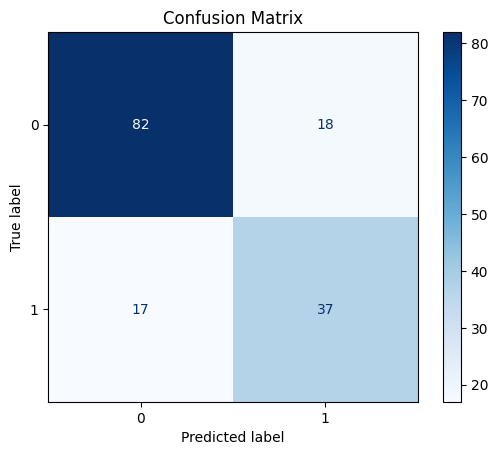

              precision    recall  f1-score   support

           0       0.83      0.82      0.82       100
           1       0.67      0.69      0.68        54

    accuracy                           0.77       154
   macro avg       0.75      0.75      0.75       154
weighted avg       0.77      0.77      0.77       154



In [67]:
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))


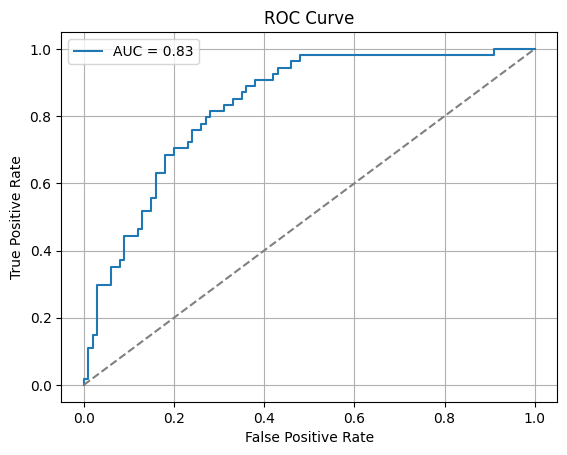

In [68]:
auc = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

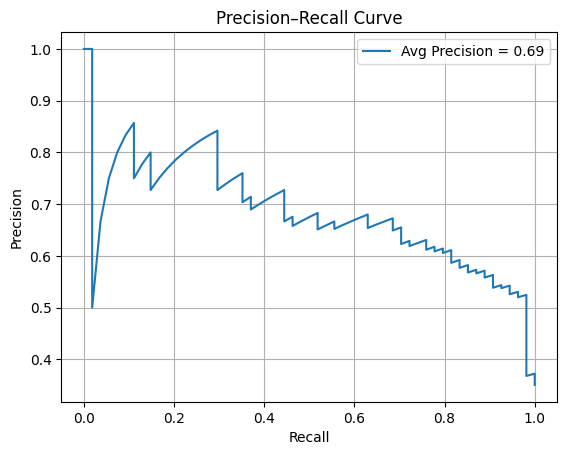

In [69]:
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
avg_precision = average_precision_score(y_test, y_pred_proba)

plt.plot(recall, precision, label=f"Avg Precision = {avg_precision:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

#### Baseline comparison

To check whether the MLP actually adds value, I compare it with two simple baselines (Logistic Regression and Random Forest). All three models use the same training data, the same held-out test set and the same 0.5 decision threshold. The baselines also use balanced class weights, like the MLP.

In [70]:
baselines = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
}

probas = {}
for name, clf in baselines.items():
    clf.fit(X_train, y_train)
    probas[name] = clf.predict_proba(X_test)[:, 1]

# MLP probabilities from the evaluation section above
probas["MLP"] = np.ravel(y_pred_proba)

In [71]:
def score_all(y_true, p, threshold=0.5):
    # all the metrics used in this notebook, computed from the predicted probabilities
    pred = (np.asarray(p) > threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, p),
        "PR AUC": average_precision_score(y_true, p),
    }

holdout_results = pd.DataFrame({name: score_all(y_test, p) for name, p in probas.items()}).T.round(3)
holdout_results

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression,0.734,0.603,0.704,0.650,0.814,0.678
Random Forest,0.740,0.659,0.537,0.592,0.837,0.715
MLP,0.773,0.673,0.685,0.679,0.832,0.689


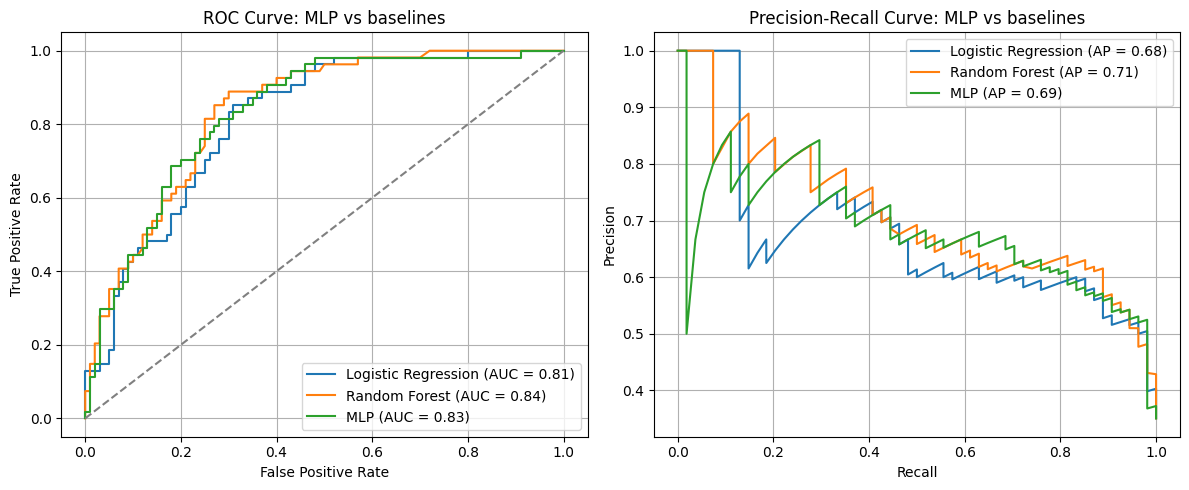

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.2f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, p):.2f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve: MLP vs baselines"); axes[0].legend(); axes[0].grid(True)

axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve: MLP vs baselines"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

#### Repeated cross-validation

The test set has only 154 patients, so differences of a point or two between models are mostly noise. To get a more reliable comparison, every model is evaluated with repeated stratified 5-fold cross-validation on the full dataset (5 folds x 3 repeats = 15 evaluations per model) and reported as mean ± standard deviation.

In every fold, imputation and scaling are fitted on that fold's training part only. All models see exactly the same folds, so the comparison is paired.

The MLP is retrained from scratch in every fold with the hyperparameters found by the tuner above, which takes a few minutes. Set `n_repeats=1` below for a quicker run.

In [73]:
X_all = df.drop(columns='Outcome')   # raw features (zeros already set to NaN, nothing imputed or scaled yet)
y_all = df['Outcome']

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
splits = list(cv.split(X_all, y_all))   # the same folds are reused for every model


def cv_scores(fit_predict):
    #Run one model over all folds. fit_predict(X_train, y_train, X_test) returns test probabilities.
    rows = []
    for train_idx, test_idx in splits:
        X_tr, X_te = X_all.iloc[train_idx], X_all.iloc[test_idx]
        y_tr, y_te = y_all.iloc[train_idx], y_all.iloc[test_idx]
        rows.append(score_all(y_te, fit_predict(X_tr, y_tr, X_te)))
    return pd.DataFrame(rows)


def mean_std(scores):
    return scores.mean().round(3).astype(str) + " ± " + scores.std().round(3).astype(str)


sk_models = {
    "Logistic Regression": lambda: LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
}


def sk_fit_predict(make_clf, make_imputer=lambda: SimpleImputer(strategy="mean")):
    def run(X_tr, y_tr, X_te):
        prep = make_preprocessor(make_imputer())
        X_tr_t = prep.fit_transform(X_tr)
        X_te_t = prep.transform(X_te)
        clf = make_clf()
        clf.fit(X_tr_t, y_tr)
        return clf.predict_proba(X_te_t)[:, 1]
    return run

##### Mean vs KNN Imputation

I put both imputers inside the pipeline, so they are fitted on the training part of each fold only.

In [74]:
imputers = {
    "Mean": lambda: SimpleImputer(strategy="mean"),
    "KNN (k=5)": lambda: KNNImputer(n_neighbors=5),
}

imp_summary = {}
for model_name, make_clf in sk_models.items():
    for imp_name, make_imp in imputers.items():
        imp_summary[f"{model_name} + {imp_name}"] = mean_std(cv_scores(sk_fit_predict(make_clf, make_imp)))

pd.DataFrame(imp_summary).T

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression + Mean,0.754 ± 0.038,0.634 ± 0.059,0.724 ± 0.054,0.673 ± 0.04,0.836 ± 0.031,0.72 ± 0.057
Logistic Regression + KNN (k=5),0.756 ± 0.04,0.636 ± 0.06,0.726 ± 0.045,0.676 ± 0.04,0.837 ± 0.031,0.721 ± 0.056
Random Forest + Mean,0.764 ± 0.033,0.694 ± 0.068,0.591 ± 0.055,0.636 ± 0.049,0.831 ± 0.034,0.712 ± 0.063
Random Forest + KNN (k=5),0.76 ± 0.028,0.683 ± 0.061,0.595 ± 0.056,0.634 ± 0.041,0.829 ± 0.035,0.709 ± 0.065


Conclusion: mean and KNN imputation give practically the same results. With Logistic Regression, KNN is only 0.001 to 0.003 higher on every metric (for example ROC AUC 0.837 vs 0.836). With Random Forest, mean imputation is slightly higher on most metrics. All these differences are much smaller than the standard deviation (about 0.03 to 0.06), so I can't say that one imputer is better than the other. I keep mean imputation because it is simpler and faster.

##### Logistic Regression vs Random Forest vs MLP

In [75]:
def mlp_fit_predict(X_tr, y_tr, X_te):
    prep = make_preprocessor()
    X_tr_t = prep.fit_transform(X_tr)
    X_te_t = prep.transform(X_te)

    cw = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_tr)

    m = tuner.hypermodel.build(best_hps)   # same architecture and tuned hyperparameters as the main model
    m.fit(X_tr_t, y_tr, epochs=200, batch_size=32,
          class_weight=dict(enumerate(cw)), verbose=0)
    p = m.predict(X_te_t, verbose=0).ravel()

    tf.keras.backend.clear_session()
    return p


cv_results = {name: cv_scores(sk_fit_predict(make_clf)) for name, make_clf in sk_models.items()}
cv_results["MLP"] = cv_scores(mlp_fit_predict)

cv_summary = pd.DataFrame({name: mean_std(s) for name, s in cv_results.items()}).T
cv_summary

c:\Users\asus\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\asus\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\asus\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in th

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression,0.754 ± 0.038,0.634 ± 0.059,0.724 ± 0.054,0.673 ± 0.04,0.836 ± 0.031,0.72 ± 0.057
Random Forest,0.764 ± 0.033,0.694 ± 0.068,0.591 ± 0.055,0.636 ± 0.049,0.831 ± 0.034,0.712 ± 0.063
MLP,0.75 ± 0.039,0.61 ± 0.048,0.797 ± 0.06,0.69 ± 0.042,0.833 ± 0.03,0.697 ± 0.054


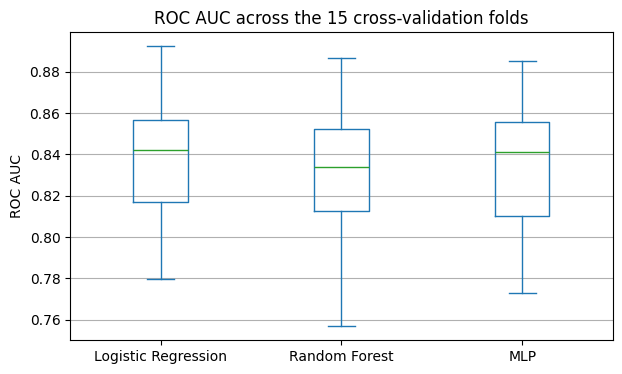

In [76]:
pd.DataFrame({name: s["ROC AUC"] for name, s in cv_results.items()}).plot.box(figsize=(7, 4))
plt.ylabel("ROC AUC")
plt.title("ROC AUC across the 15 cross-validation folds")
plt.grid(True, axis="y")
plt.show()

##### Limitations

- I tuned the MLP hyperparameters once, on a single training/validation split that overlaps with some of the cross-validation test folds, so its cross-validated scores may be slightly optimistic. A fair comparison would run the tuner inside each fold (nested cross-validation), but that is much slower.
- The 15 folds from repeated cross-validation are not fully independent, so the standard deviation slightly understates the real uncertainty.